# Hari 1, Sesi 0: Persiapan Google Colab untuk Ekonometrika

**Durasi:** 30 menit

Notebook ini untuk dosen atau pengajar. Isinya: menyiapkan lingkungan kerja,
menyiapkan data, dan mengenali padanan perintah EViews dengan Python.

**Sebelum mulai:** Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.

Cara menjalankan sel: klik selnya, tekan `Shift + Enter`.



**Posisi dalam alur workshop.** Sesi pembuka: menyiapkan alat dan data.
Semua sesi setelah ini memakai pola yang sama, yaitu muat data, estimasi
model, baca output, uji, lalu interpretasi.



**Alur sesi:** kenali arti kolom, baca data Indonesia dari beberapa format,
bandingkan hasil tabelnya, lalu buat grafik. Setelah itu, lanjutkan contoh
regresi pertama. Jalankan sel berurutan; semua pembacaan data sudah disiapkan.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


## 1. Cek lingkungan

Pandas mengolah tabel; matplotlib dan seaborn membuat grafik. Sel berikut
menambahkan pembaca Excel (`openpyxl`), SPSS (`pyreadstat`), dan Parquet (`pyarrow`).
`linearmodels` dan `arch` disiapkan untuk materi panel dan GARCH berikutnya.
`%pip install` memasang paket di runtime notebook. Tunggu sampai sel selesai.

In [2]:
%pip install -q "linearmodels==7.1" "arch==8.0.0" "openpyxl==3.1.5" "pyreadstat==1.3.2" "pyarrow==19.0.0"

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

print("Python", sys.version.split()[0])
print("pandas", pd.__version__)
print("statsmodels", sm.__version__)
print("scikit-learn", sklearn.__version__)



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


Python 3.13.5
pandas 2.2.3
statsmodels 0.15.0
scikit-learn 1.6.1


## 2. Membaca data Indonesia dalam berbagai format

Data dari rekan peneliti dapat berbentuk Excel, SPSS, atau Stata. Pandas
mengubah tabel-tabel itu menjadi bentuk yang sama: **DataFrame**, yaitu tabel
dengan baris dan kolom. Pilih perintah baca sesuai jenis berkasnya.

Kita memakai **satu tabel makro Indonesia, 2000 sampai 2025**, dari World Bank.
Satu baris mewakili satu tahun. Semua contoh memuat **26 baris dan tujuh kolom**.
CSV sumber sudah ada di `data/idn_makro_tahunan.csv`; enam salinan format lain
dikumpulkan di `data/contoh_format/`. Angka dan nama kolom dipertahankan agar
perbandingannya mudah. SPSS dan Stata di sini adalah hasil konversi untuk latihan,
bukan berkas mikrodata survei asli.

| Jenis berkas | Akhiran | Perintah pandas |
|---|---|---|
| CSV, teks dengan pemisah koma | `.csv` | `pd.read_csv(...)` |
| Microsoft Excel | `.xlsx` | `pd.read_excel(...)` |
| Data SPSS | `.sav` | `pd.read_spss(...)` |
| Data Stata | `.dta` | `pd.read_stata(...)` |
| Teks dengan pemisah tab | `.tsv` | `pd.read_csv(..., sep="\t")` |
| Tabel JSON | `.json` | `pd.read_json(...)` |
| Tabel Parquet | `.parquet` | `pd.read_parquet(...)` |

Jalankan empat contoh pertama bersama pengajar. TSV, JSON, dan Parquet dapat
dipelajari setelahnya. Berkas dibaca atau diunduh otomatis; tidak perlu unggah ZIP.

Sumber: [World Bank Indonesia](https://data.worldbank.org/country/indonesia),
[pertumbuhan PDB](https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG?locations=ID),
dan [inflasi IHK](https://data.worldbank.org/indicator/FP.CPI.TOTL.ZG?locations=ID).
Salinan latihan mengikuti lisensi CC BY 4.0.

In [4]:
URL_FORMAT = URL_DATA + "contoh_format/"

### A. CSV: pemisah koma

`pd` adalah nama singkat pandas. `read_csv` membaca berkas, sedangkan
`makro_csv` menyimpan tabel hasilnya. `head()` menampilkan lima baris pertama.
Baca dahulu arti kolom pada tabel **Kenali data** di bawah.

<!-- kamus_variabel:idn_makro_tahunan.csv -->

### Kenali data: Makroekonomi Indonesia tahunan

**Data:** `data/idn_makro_tahunan.csv`. **Satu baris:** satu tahun kalender untuk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `negara` | Kode negara; IDN menunjukkan Indonesia. | Kode ISO negara | Penanda, bukan besaran ekonomi |
| `tahun` | Tahun kalender pengamatan. | Tahun | Penanda waktu |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG | Target pertumbuhan pada model panel |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG | Y atau X sesuai model |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS | X: penjelas |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF | X: penjelas |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN | X: penjelas |

Kurs_USD untuk Indonesia bersatuan rupiah per US$1. Inflasi dan pertumbuhan adalah laju persen, bukan nilai level harga atau level PDB.

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


In [5]:
makro_csv = pd.read_csv(URL_DATA + "idn_makro_tahunan.csv")
makro_csv.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


`negara` berisi `IDN`, yaitu Indonesia. `tahun` berisi tahun kalender.
Angka pada kolom PDB, inflasi, dan pengangguran adalah persentase, sedangkan
kurs dinyatakan dalam rupiah per dolar AS. Data ini dipakai lagi pada kasus
Indonesia di Lab 6; pada tahap ini kita belajar membaca dan mengenali tabelnya.

### B. Excel: pilih lembar yang berisi data

Berkas ini memiliki lembar `data` dan `sumber`. `sheet_name="data"` memilih
lembar angka; lembar `sumber` berisi definisi dan asal data.

In [6]:
makro_excel = pd.read_excel(URL_FORMAT + "idn_makro_tahunan.xlsx", sheet_name="data")
makro_excel.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### C. SPSS: unduh, lalu baca berkas `.sav`

`read_spss` memerlukan berkas lokal. `urlretrieve` mengunduh salinannya ke
runtime notebook dengan nama yang kita tentukan. Baris berikutnya membaca
berkas tersebut menjadi tabel pandas. Sel instalasi sudah menyiapkan `pyreadstat`.
Tidak perlu membuka aplikasi SPSS.

In [7]:
from urllib.request import urlretrieve

urlretrieve(URL_FORMAT + "idn_makro_tahunan.sav", "idn_makro_tahunan.sav")
makro_spss = pd.read_spss("idn_makro_tahunan.sav")
makro_spss.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000.0,4.920068,3.688620,6.077,8421.775000,101308307.0
1,IDN,2001.0,3.643466,11.500116,6.082,10260.850000,102354432.0
2,IDN,2002.0,4.499475,11.900120,6.604,9311.191667,102498864.0
3,IDN,2003.0,4.780369,6.757313,6.657,8577.133333,103909546.0
4,IDN,2004.0,5.030874,6.064062,7.303,8938.850000,105759801.0


### D. Stata: baca berkas `.dta`

`read_stata` dapat langsung membaca alamat berkas. `.dta` menyimpan data;
berkas `.do` adalah script Stata, sehingga tidak dibaca sebagai tabel.

In [8]:
makro_stata = pd.read_stata(URL_FORMAT + "idn_makro_tahunan.dta")
makro_stata.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### E. TSV: teks dengan pemisah tab

CSV dan TSV sama-sama berupa teks. `sep="\t"` menjelaskan bahwa batas antarkolom
adalah tab. Untuk berkas berpemisah titik koma, gunakan `sep=";"`.

In [9]:
makro_tsv = pd.read_csv(URL_FORMAT + "idn_makro_tahunan.tsv", sep="\t")
makro_tsv.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### F. JSON: daftar catatan

JSON sering dipakai untuk pertukaran data melalui web. Pada contoh yang sudah
disiapkan ini, satu catatan mewakili satu tahun. `orient="records"` menyatakan
susunan tersebut. JSON dari situs lain dapat memiliki struktur bertingkat
yang perlu dirapikan terlebih dahulu.

In [10]:
makro_json = pd.read_json(URL_FORMAT + "idn_makro_tahunan.json", orient="records")
makro_json.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### G. Parquet: penyimpanan tabel per kolom

Parquet sering dipakai untuk menyimpan tabel dalam proyek analisis data.
Perintah bacanya tetap pendek; paket `pyarrow` sudah disiapkan pada sel instalasi.

In [11]:
makro_parquet = pd.read_parquet(URL_FORMAT + "idn_makro_tahunan.parquet")
makro_parquet.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### Periksa hasil baca sebelum menganalisis

`shape` menampilkan pasangan jumlah baris dan kolom. Tujuh hasil baca berikut
seharusnya sama-sama `(26, 7)`. Bandingkan pula lima baris pertama di atas:
tahun, nama kolom, dan nilainya tetap sama meskipun format berkas berbeda.

In [12]:
print("CSV     :", makro_csv.shape)
print("Excel   :", makro_excel.shape)
print("SPSS    :", makro_spss.shape)
print("Stata   :", makro_stata.shape)
print("TSV     :", makro_tsv.shape)
print("JSON    :", makro_json.shape)
print("Parquet :", makro_parquet.shape)

CSV     : (26, 7)
Excel   : (26, 7)
SPSS    : (26, 7)
Stata   : (26, 7)
TSV     : (26, 7)
JSON    : (26, 7)
Parquet : (26, 7)


### Dari tabel SPSS menjadi grafik

Setelah dibaca, hasilnya adalah tabel pandas atau **DataFrame**. Perintah grafiknya
sama seperti untuk CSV atau Excel. Kita memakai kolom `tahun` dan `Inflasi`.

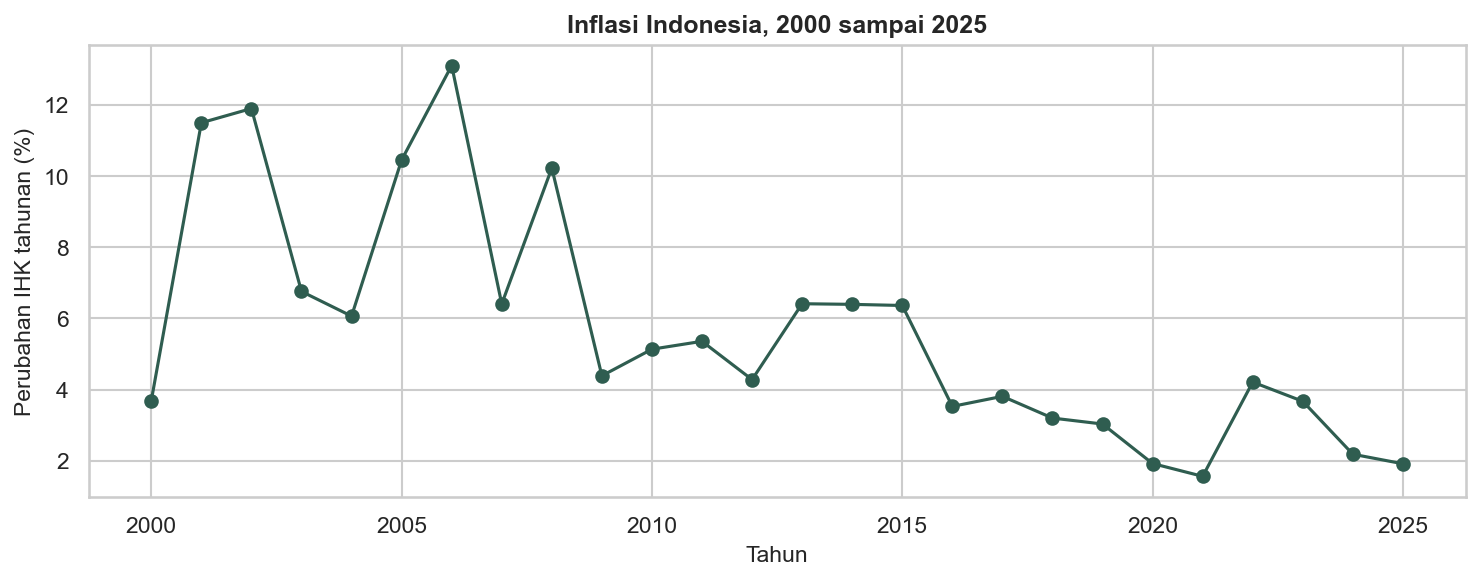

In [13]:
makro_spss.plot(x="tahun", y="Inflasi", marker="o", color="#2F5D50",
                figsize=(10, 4), legend=False)
plt.title("Inflasi Indonesia, 2000 sampai 2025")
plt.xlabel("Tahun")
plt.ylabel("Perubahan IHK tahunan (%)")
plt.xticks([2000, 2005, 2010, 2015, 2020, 2025])
plt.tight_layout()
plt.show()

**Cara membaca:** satu titik menunjukkan inflasi Indonesia pada satu tahun.
Sumbu mendatar menunjukkan tahun; sumbu tegak menunjukkan perubahan tahunan
Indeks Harga Konsumen (IHK) dalam persen. Misalnya, nilai 5 berarti IHK naik
sekitar 5 persen dari tahun sebelumnya. Garis membantu melihat perubahan antarwaktu.
Grafik ini berasal dari berkas SPSS, tetapi isinya sama dengan tabel CSV sumber.
Ukuran inflasi tahunan World Bank ini jangan disamakan begitu saja dengan inflasi
bulanan atau angka Desember terhadap Desember.

### Batas yang perlu dikenali

Pandas mendukung banyak format tabel, tetapi tidak membaca semua jenis berkas
secara langsung. `.sps` adalah script SPSS; data SPSS pada contoh ini memakai
`.sav`. Untuk EViews `.wf1`, ekspor dahulu ke CSV atau Excel. Tabel pada PDF,
foto, atau hasil pindai perlu diekstrak menjadi tabel sebelum dianalisis.
Data SAS dan basis data memiliki pembaca lain, yaitu `read_sas` dan `read_sql`,
dengan persiapan yang disesuaikan sumbernya.

Dokumentasi: [pembaca data pandas](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/io.html),
[Excel](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.read_excel.html),
[SPSS](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.read_spss.html),
dan [Stata](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.read_stata.html).

Kita sudah melihat bahwa berbagai format menghasilkan tabel pandas. Berikutnya,
kita kembali memakai CSV untuk kasus iklan dan penjualan, lalu membuat model pertama.

## 3. Baca kasus iklan dan penjualan

`URL_DATA` menyimpan alamat folder CSV di GitHub. Cara membacanya satu baris:
`pd.read_csv(URL_DATA + "regresi_polinom.csv")`.



<!-- kamus_variabel:regresi_polinom.csv -->

### Kenali data: Iklan dan penjualan

**Data:** `data/regresi_polinom.csv`. **Satu baris:** satu tahun pengamatan pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun ke-` | `Tahun ke-` | Urutan tahun pengamatan, bukan tahun kalender. | 1, 2, 3, dan seterusnya | Penanda waktu |
| `Biaya Iklan (X)` | `iklan` | Biaya yang dikeluarkan untuk memasang iklan. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Penjualan (Y)` | `penjualan` | Besarnya penjualan yang ingin dijelaskan oleh biaya iklan. | Satuan/skala tidak dirinci sumber | Y: target |

Jangan menetapkan rupiah, juta rupiah, atau unit barang hanya dari besar angkanya; skala tersebut tidak dicantumkan pada sumber tabel.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [14]:
data = pd.read_csv(URL_DATA + "regresi_polinom.csv")
print("Ukuran data:", data.shape)
data.head()


Ukuran data: (30, 3)


,Tahun ke-,Biaya Iklan (X),Penjualan (Y)
0,1,5.0,30.1
1,2,6.5,36.2
2,3,8.0,42.5
3,4,9.5,48.8
4,5,11.0,54.1


## 4. Sel pertama yang berguna: satu grafik

Sebelum masuk regresi, lihat datanya dulu. Satu scatter plot bisa
menyelamatkan Anda dari salah spesifikasi yang mahal.



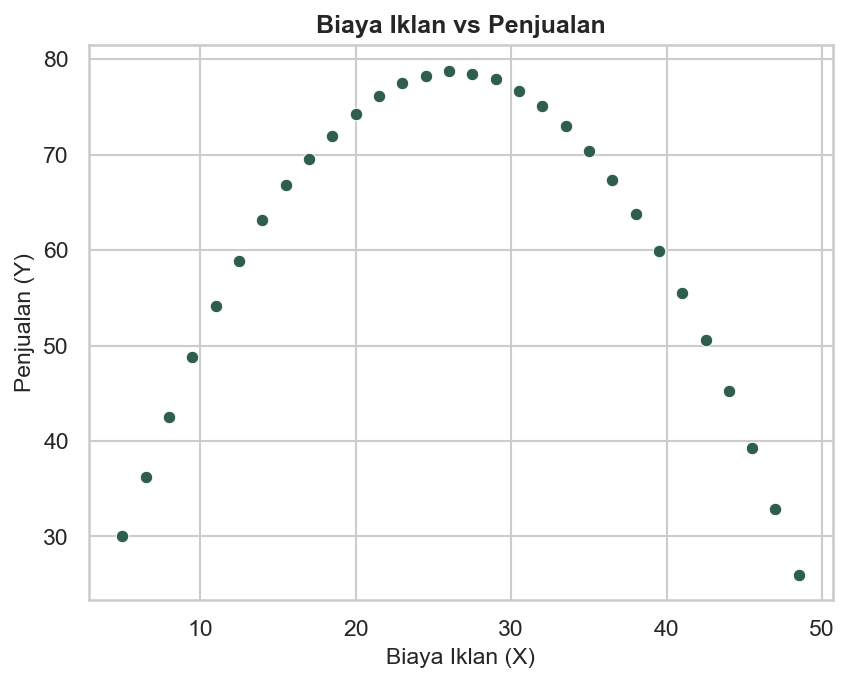

In [15]:
sns.scatterplot(data=data, x="Biaya Iklan (X)", y="Penjualan (Y)")
plt.title("Biaya Iklan vs Penjualan")
plt.show()


**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

## 5. Membaca rumus model dan angka penting

Simbol `~` dibaca "dijelaskan oleh". Jadi `penjualan ~ iklan` berarti
penjualan dijelaskan oleh iklan. `fit()` menghitung koefisiennya.
Di sini model garis lurus hanya contoh awal; bentuk lengkung dibahas di Sesi 2.



In [16]:
polinom = data.rename(
    columns={"Biaya Iklan (X)": "iklan", "Penjualan (Y)": "penjualan"}
)
sampel_model = polinom[["penjualan", "iklan"]].dropna()
X_model = sampel_model[["iklan"]]
y_model = sampel_model["penjualan"]

model = LinearRegression()
model.fit(X_model, y_model)


LinearRegression()

### Lihat hasil model: Penjualan (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

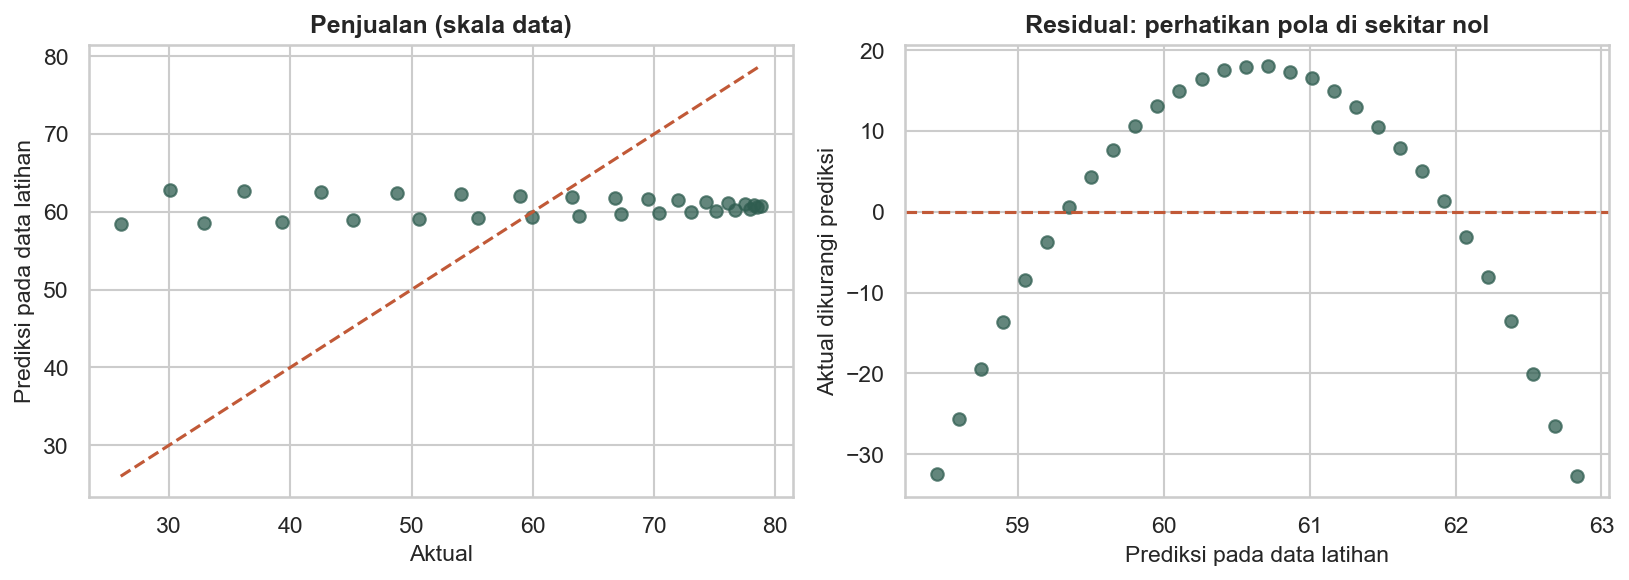

In [17]:
prediksi_visual = model.predict(X_model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model.min(), y_model.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Penjualan (skala data)")
axes[1].scatter(prediksi_visual, y_model - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya. Pada contoh ini residual justru melengkung: hubungan iklan dan penjualan memang belum cocok dengan garis lurus. Ini bahan yang akan kita lanjutkan pada pemilihan bentuk model di Sesi 1–2.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [18]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()


In [19]:
# Baca satu angka setiap baris. Tidak perlu membuat fungsi Python sendiri.
print("Jumlah observasi:", uji_model.nobs)
print("R kuadrat:", model.score(X_model, y_model))
print("R kuadrat terkoreksi:", uji_model.rsquared_adj)
print("p-value uji F:", uji_model.f_pvalue)
print("AIC:", uji_model.aic)


Jumlah observasi: 30.0
R kuadrat: 0.0065772980467725395
R kuadrat terkoreksi: -0.0289020841658425
p-value uji F: 0.670083095460895
AIC: 255.84470425068557


### Coba sendiri (5 menit)

Baca `data/uts_4.csv` ke variabel baru, lalu tampilkan jumlah baris dan
rata-rata kolom `Y_Angka_Harapan_Hidup`. Butuh berapa baris kode?

Tulis di sel di bawah, baru buka jawabannya.



In [20]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

Dua baris: `uts4 = pd.read_csv(URL_DATA + "uts_4.csv")` lalu
`print(len(uts4), uts4["Y_Angka_Harapan_Hidup"].mean())`.
Hasilnya 50 baris dan rata-rata 76,95.

</details>



## 6. Padanan perintah EViews dan Python

Materi kuliah memakai EViews. Tabel ini jembatannya:

| EViews | Python dalam tutorial |
|---|---|
| `ls y c x1 x2` | `LinearRegression().fit(X, y)`; X berisi x1 dan x2 |
| `ls log(y) c log(x)` | Buat kolom log, lalu `LinearRegression().fit(X_log, y_log)` |
| Method **BINARY - Logit** | `LogisticRegression().fit(X, y)` |
| Method **BINARY - Probit** | `smf.probit("y ~ x1", data=df).fit()` |
| Method **ORDERED** | `OrderedModel(...)` dari statsmodels |
| Method **COUNT - Poisson** | `PoissonRegressor(alpha=0).fit(X, y)` |
| Method **ARCH - GARCH(1,1)** | `arch_model(y, vol="Garch", p=1, q=1)` |
| Options > White robust SE | `.fit(cov_type="HC3")` |
| Panel Options: Fixed | `PanelOLS(..., entity_effects=True)` |

Nama kolom output juga beda, artinya sama:

| EViews | statsmodels | Arti |
|---|---|---|
| Coefficient | `coef` | koefisien |
| Std. Error | `std err` | galat baku |
| t-Statistic | `t` | statistik uji |
| Prob. | `pvalue` (ditulis P di output) | p-value |
| R-squared | `rsquared` | proporsi variasi terjelaskan |

### Dua pustaka Python dan porsinya

- **scikit-learn**: model utama, koefisien, prediksi, pembagian data,
  dan evaluasi. Polanya sama: X, y, model, fit, predict.
- **statsmodels**: pelengkap inferensi dan diagnostik, serta model khusus
  seperti probit, ordinal, dan ARIMA. Data panel memakai **linearmodels**,
  sedangkan GARCH memakai **arch**.

OLS tetap metode estimasi `LinearRegression`. Nama `uji_...` membantu
membedakan pelengkap statistik dari model utama scikit-learn.

## 7. Peta materi semester ke notebook ini

| Pertemuan kuliah | Topik | Notebook |
|---|---|---|
| 1-2 | Regresi linear dan bentuk fungsional | `01`, `02` |
| 3-4 | Variabel dummy, multikolinearitas | `03` |
| 5-7 | Heteroskedastisitas, normalitas, autokorelasi | `03` |
| 9-10 | Logit, probit, multinomial, ordinal | `04` |
| 11 | Tobit dan Poisson | `04` |
| 12-13 | Deret waktu, kointegrasi, ECM | `05` |
| 14-15 | GARCH, data panel | `06` |

Dua hari tidak cukup menuntaskan 16 pertemuan. Yang dikejar di workshop
ini: alur kerja lengkap dari data sampai interpretasi, plus contoh kode
untuk setiap topik. Sisanya latihan mandiri.



## Latihan singkat

1. Baca `data/uts_4.csv` (data harapan hidup). Tampilkan 5 baris pertama.
2. Berapa jumlah observasi dan berapa rata-rata `Y_Angka_Harapan_Hidup`?

(Kunci ada di `pengajar/README.md#pembahasan-latihan`.)



<!-- kamus_variabel:uts_4.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/uts_4.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [21]:
# Tulis jawaban Anda di sini
# uts4 = pd.read_csv(URL_DATA + "uts_4.csv")
# ...


## Praktik pendampingan AI

Setelah contoh regresi berjalan, salin satu sel dan minta AI:

> Saya baru belajar coding. Jelaskan kode ini satu baris setiap kali
> dalam bahasa Indonesia. Sebutkan masukannya, hasil yang disimpan,
> serta bagian yang boleh saya ubah. Gunakan nama yang sama dan
> jangan menambahkan fungsi buatan sendiri atau perulangan.

Cocokkan penjelasannya dengan tabel data dan hasil kode yang dijalankan.
AI tidak perlu menebak koefisien. Ganti satu nilai prediksi, jalankan ulang,
lalu tulis kesimpulan sendiri dengan satuan yang benar. Contoh prompt
untuk membaca output dan memahami error ada di pengajar/README.md#pendampingan-ai.



### Selanjutnya

Selanjutnya: Sesi 1, model regresi pertama.
